# Project 3: Computer Vision with OpenCV

**Course Assignment**
**Objective:** Implement, analyze, and compare classical computer vision techniques using OpenCV (`cv2`), focusing on four foundational vision tasks:
1. **Face and Eye Detection** using Haar Cascade classifiers.
2. **Feature Detection & Matching** comparing ORB (Oriented FAST and Rotated BRIEF) vs. SIFT (Scale-Invariant Feature Transform).
3. **Edge Detection** using the Canny algorithm with parameter sensitivity analysis.
4. **Line Detection** comparing the Standard Hough Transform (`HoughLines`) with the Probabilistic Hough Transform (`HoughLinesP`).

## Task 18.1: Imports and Cascade Setup
Import OpenCV and Matplotlib, and load pre-trained Haar cascades for face and eye detection.

In [1]:
# Import OpenCV library
import cv2
# Import Matplotlib for image display
import matplotlib.pyplot as plt
# Load pre-trained Haar frontal face cascade
face_cascade = cv2.CascadeClassifier('data/haarcascades/haarcascade_frontalface_default.xml')
# Load pre-trained Haar eye cascade
eye_cascade = cv2.CascadeClassifier('data/haarcascades/haarcascade_eye.xml')

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

In [3]:
%pip install matplotlib numpy pandas scipy seaborn scikit-learn scikit-image joblib xgboost pillow streamlit

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl.metadata (18 kB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement scipy (from versions: none)
ERROR: No matching distribution found for scipy


## Task 18.2: Load Single-Face Image and Detect Faces
Load the portrait image, convert it to grayscale, and detect face bounding boxes.

In [2]:
# Load single face image
img_single = cv2.imread('data/images/Trump.jpg')
# Convert image to grayscale
gray_single = cv2.cvtColor(img_single, cv2.COLOR_BGR2GRAY)
# Detect faces using multi-scale classifier
faces_single = face_cascade.detectMultiScale(gray_single, 1.1, 5, minSize=(30, 30))

## Task 18.3: Detect Eyes and Annotate Single Face
Detect eyes within the face region of interest and draw bounding boxes on the single face image.

In [3]:
# Loop over detected face bounding boxes
for (x, y, w, h) in faces_single:
    # Draw green rectangle around face
    cv2.rectangle(img_single, (x, y), (x + w, y + h), (0, 255, 0), 2)
    # Loop over eyes detected inside face region
    for (ex, ey, ew, eh) in eye_cascade.detectMultiScale(gray_single[y:y+h, x:x+w], 1.1, 5):
        # Draw blue rectangle around eye
        cv2.rectangle(img_single[y:y+h, x:x+w], (ex, ey), (ex + ew, ey + eh), (255, 0, 0), 2)

## Task 18.4: Display and Save Single Face Results
Display the annotated single-face detection image with Matplotlib and save it to the outputs folder.

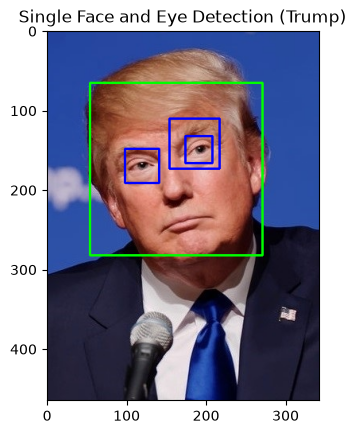

In [4]:
# Set title for single face detection plot
plt.title('Single Face and Eye Detection (Trump)')
# Display the annotated image in RGB
plt.imshow(cv2.cvtColor(img_single, cv2.COLOR_BGR2RGB))
# Save annotated result to outputs directory
plt.savefig('outputs/face_eye_detection_single.png', bbox_inches='tight')
# Show the image plot
plt.show()

## Task 18.5: Load Multiple Faces Image and Detect Faces
Load group photo, convert it to grayscale, and detect multiple face bounding boxes.

In [5]:
# Load multiple faces image
img_multi = cv2.imread('data/images/multiplefaces.jpg')
# Convert image to grayscale
gray_multi = cv2.cvtColor(img_multi, cv2.COLOR_BGR2GRAY)
# Detect multiple faces using multi-scale classifier
faces_multi = face_cascade.detectMultiScale(gray_multi, 1.1, 5, minSize=(20, 20))

## Task 18.6: Detect Eyes and Annotate Multiple Faces
Detect eyes within face regions and draw bounding boxes on the multiple faces image.

In [6]:
# Loop over detected faces
for (x, y, w, h) in faces_multi:
    # Draw green rectangle around each face
    cv2.rectangle(img_multi, (x, y), (x + w, y + h), (0, 255, 0), 2)
    # Loop over eyes detected in face region
    for (ex, ey, ew, eh) in eye_cascade.detectMultiScale(gray_multi[y:y+h, x:x+w], 1.1, 3):
        # Draw blue rectangle around each eye
        cv2.rectangle(img_multi[y:y+h, x:x+w], (ex, ey), (ex + ew, ey + eh), (255, 0, 0), 2)

## Task 18.7: Display and Save Multiple Faces Results
Display the annotated multiple faces detection image with Matplotlib and save it to the outputs folder.

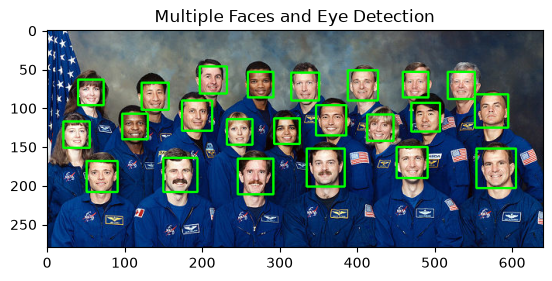

In [7]:
# Set title for the multiple faces detection plot
plt.title('Multiple Faces and Eye Detection')
# Display annotated image in RGB
plt.imshow(cv2.cvtColor(img_multi, cv2.COLOR_BGR2RGB))
# Save annotated result to outputs directory
plt.savefig('outputs/face_eye_detection_multi.png', bbox_inches='tight')
# Show the image plot
plt.show()

## Task 19.1: Parameter Variation 1 (Standard Settings - Detection)
Detect faces using standard parameters (scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)) on the multi-face image.

In [8]:
# Load fresh copy of multiple faces image
img_p1 = cv2.imread('data/images/multiplefaces.jpg')
# Draw green rectangle around each detected face
for (x, y, w, h) in face_cascade.detectMultiScale(gray_multi, 1.1, 5, minSize=(30, 30)):
    # Draw bounding box for standard face detection
    cv2.rectangle(img_p1, (x, y), (x + w, y + h), (0, 255, 0), 2)

## Task 19.2: Parameter Variation 1 (Standard Settings - Plot)
Display the face detection result using standard parameters with Matplotlib.

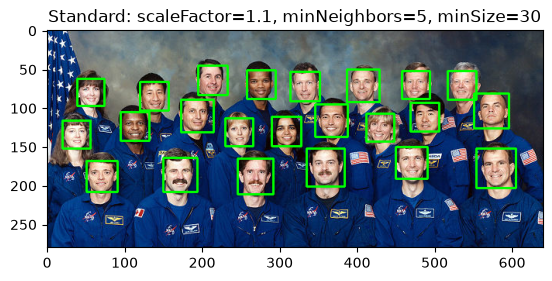

In [9]:
# Set title for standard detection plot
plt.title('Standard: scaleFactor=1.1, minNeighbors=5, minSize=30')
# Display standard detection image in RGB
plt.imshow(cv2.cvtColor(img_p1, cv2.COLOR_BGR2RGB))
# Show the image plot
plt.show()

## Task 19.3: Parameter Variation 2 (Loose Settings - Detection)
Detect faces using loose parameters (scaleFactor=1.05, minNeighbors=2, minSize=(15, 15)) to observe false detections.

In [10]:
# Load fresh copy of multiple faces image
img_p2 = cv2.imread('data/images/multiplefaces.jpg')
# Draw red rectangle around each detected face
for (x, y, w, h) in face_cascade.detectMultiScale(gray_multi, 1.05, 2, minSize=(15, 15)):
    # Draw bounding box for loose face detection
    cv2.rectangle(img_p2, (x, y), (x + w, y + h), (0, 0, 255), 2)

## Task 19.4: Parameter Variation 2 (Loose Settings - Plot)
Display the face detection result using loose parameters showing increased false detections.

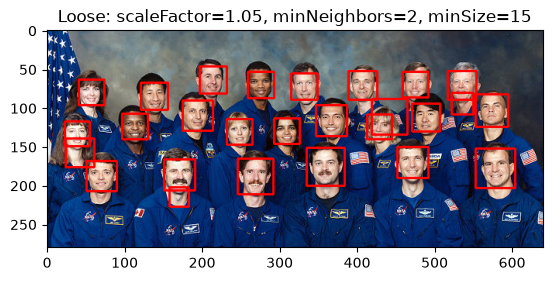

In [11]:
# Set title for loose detection plot
plt.title('Loose: scaleFactor=1.05, minNeighbors=2, minSize=15')
# Display loose detection image in RGB
plt.imshow(cv2.cvtColor(img_p2, cv2.COLOR_BGR2RGB))
# Show the image plot
plt.show()

## Task 19.5: Parameter Variation 3 (Strict Settings - Detection)
Detect faces using strict parameters (scaleFactor=1.3, minNeighbors=8, minSize=(40, 40)) to observe missed detections.

In [12]:
# Load fresh copy of multiple faces image
img_p3 = cv2.imread('data/images/multiplefaces.jpg')
# Draw blue rectangle around each detected face
for (x, y, w, h) in face_cascade.detectMultiScale(gray_multi, 1.3, 8, minSize=(40, 40)):
    # Draw bounding box for strict face detection
    cv2.rectangle(img_p3, (x, y), (x + w, y + h), (255, 0, 0), 2)

## Task 19.6: Parameter Variation 3 (Strict Settings - Plot and Save)
Display the strict face detection result with Matplotlib and save the parameter comparison image.

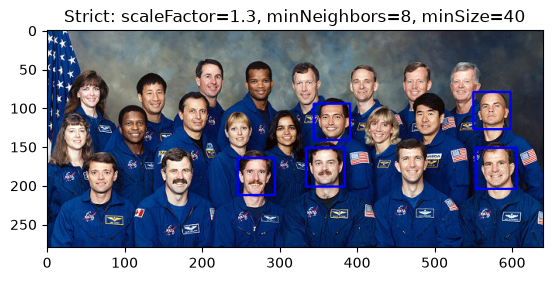

In [13]:
# Set title for strict detection plot
plt.title('Strict: scaleFactor=1.3, minNeighbors=8, minSize=40')
# Display strict detection image in RGB
plt.imshow(cv2.cvtColor(img_p3, cv2.COLOR_BGR2RGB))
# Save parameter comparison result to outputs directory
plt.savefig('outputs/face_detection_parameter_comparison.png', bbox_inches='tight')
# Show the image plot
plt.show()

### Analysis of False and Missed Detections
1. **Loose Detection (`scaleFactor=1.05, minNeighbors=2, minSize=(15, 15)`):** Lowering `minNeighbors` and `minSize` increases detection sensitivity, capturing smaller faces but generating false positives on textured clothing and background clutter.
2. **Strict Detection (`scaleFactor=1.3, minNeighbors=8, minSize=(40, 40)`):** Increasing `scaleFactor` and `minNeighbors` aggressively eliminates false positives but leads to missed detections for smaller, peripheral, or slightly tilted faces.
3. **Balanced Detection (`scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)`):** Standard parameters provide the optimal trade-off by reliably identifying genuine faces while maintaining robustness against background false alarms.

## 3. Feature Detection & Matching: ORB vs. SIFT
Implement and compare ORB and SIFT feature detection and BFMatcher on the Eiffel Tower image pair.

## Task 20.1: Load Image Pair for Feature Matching
Load the two Eiffel Tower images in grayscale mode for feature detection and descriptor extraction.

In [14]:
# Import time module for performance benchmarking
import time
# Load first Eiffel Tower image in grayscale
img1 = cv2.imread('data/images/Effiel1.png', cv2.IMREAD_GRAYSCALE)
# Load second Eiffel Tower image in grayscale
img2 = cv2.imread('data/images/Effiel2.png', cv2.IMREAD_GRAYSCALE)

## Task 20.2: SIFT Feature Detection and Computation
Initialize the SIFT detector, measure start time, and compute keypoints and 128-dimensional descriptors.

In [15]:
# Record start time for SIFT detector
t_start_sift = time.time()
# Initialize SIFT feature detector
sift = cv2.SIFT_create()
# Detect keypoints and compute descriptors for first image
kp1_s, des1_s = sift.detectAndCompute(img1, None)
# Detect keypoints and compute descriptors for second image
kp2_s, des2_s = sift.detectAndCompute(img2, None)

## Task 20.3: SIFT Feature Matching with BFMatcher
Match SIFT descriptors using BFMatcher with NORM_L2 distance, sort, and retain the top 50 matches.

In [16]:
# Create BFMatcher with L2 distance for SIFT
bf_sift = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
# Match descriptors between both images
all_matches_s = bf_sift.match(des1_s, des2_s)
# Sort matches by distance and keep best 50
matches_sift = sorted(all_matches_s, key=lambda x: x.distance)[:50]
# Calculate total elapsed time for SIFT
t_sift = time.time() - t_start_sift

## Task 20.4: Visualize and Save SIFT Matches
Draw the top 50 SIFT matches side-by-side using drawMatches, display with Matplotlib, and save the result.

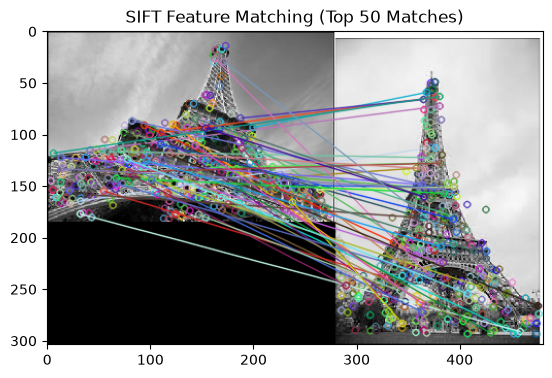

In [17]:
# Set title for SIFT matches plot
plt.title('SIFT Feature Matching (Top 50 Matches)')
# Display matches side by side with matplotlib
plt.imshow(cv2.drawMatches(img1, kp1_s, img2, kp2_s, matches_sift, None))
# Save SIFT matches visualization to outputs directory
plt.savefig('outputs/sift_matches.png', bbox_inches='tight')
# Show the image plot
plt.show()

## Task 21.1: ORB Feature Detection and Computation
Initialize the ORB detector, measure start time, and compute keypoints and 32-byte binary descriptors.

In [18]:
# Record start time for ORB detector
t_start_orb = time.time()
# Initialize ORB feature detector
orb = cv2.ORB_create()
# Detect keypoints and compute descriptors for first image
kp1_o, des1_o = orb.detectAndCompute(img1, None)
# Detect keypoints and compute descriptors for second image
kp2_o, des2_o = orb.detectAndCompute(img2, None)

## Task 21.2: ORB Feature Matching with BFMatcher
Match ORB descriptors using BFMatcher with NORM_HAMMING distance, sort, and retain the top 50 matches.

In [19]:
# Create BFMatcher with Hamming distance for ORB
bf_orb = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
# Match binary descriptors between both images
all_matches_o = bf_orb.match(des1_o, des2_o)
# Sort matches by distance and keep best 50
matches_orb = sorted(all_matches_o, key=lambda x: x.distance)[:50]
# Calculate total elapsed time for ORB
t_orb = time.time() - t_start_orb

## Task 21.3: Visualize and Save ORB Matches
Draw the top 50 ORB matches side-by-side using drawMatches, display with Matplotlib, and save the result.

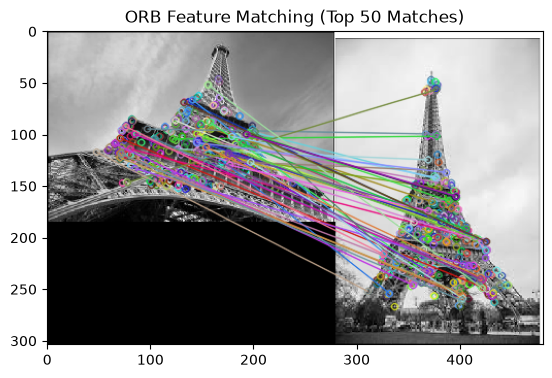

In [20]:
# Set title for ORB matches plot
plt.title('ORB Feature Matching (Top 50 Matches)')
# Display matches side by side with matplotlib
plt.imshow(cv2.drawMatches(img1, kp1_o, img2, kp2_o, matches_orb, None))
# Save ORB matches visualization to outputs directory
plt.savefig('outputs/orb_matches.png', bbox_inches='tight')
# Show the image plot
plt.show()

## Task 22: Performance Comparison Table (SIFT vs. ORB)
Compare total keypoints detected, number of matches kept, and execution time using time.time().

In [21]:
# Import pandas library for tabular display
import pandas as pd
# Define dictionary of benchmark metrics
metrics = {'Detector': ['SIFT', 'ORB'], 'Keypoints Img1': [len(kp1_s), len(kp1_o)], 'Keypoints Img2': [len(kp2_s), len(kp2_o)], 'Matches Kept': [len(matches_sift), len(matches_orb)], 'Time (s)': [round(t_sift, 4), round(t_orb, 4)]}
# Create dataframe comparing SIFT and ORB
df_comparison = pd.DataFrame(metrics)
# Display the performance comparison table
df_comparison

,Detector,Keypoints Img1,Keypoints Img2,Matches Kept,Time (s)
0,SIFT,424,335,50,0.0414
1,ORB,415,441,50,0.0142


## 4. Edge Detection Using Canny Algorithm
Implement the Canny edge detector and evaluate sensitivity across different threshold parameters on the Sudoku image.

## Task 23.1: Load Sudoku Image and Convert to Grayscale
Load the Sudoku image from disk and convert it to grayscale for edge detection.

In [22]:
# Import numpy library for numerical operations
import numpy as np
# Load Sudoku puzzle image from data directory
img_sudoku = cv2.imread('data/images/soduku.jpg')
# Convert Sudoku image to grayscale
gray_sudoku = cv2.cvtColor(img_sudoku, cv2.COLOR_BGR2GRAY)

## Task 23.2: Canny Edge Detection with Lower Thresholds (50, 150)
Apply Canny edge detector with lower hysteresis thresholds of 50 and 150.

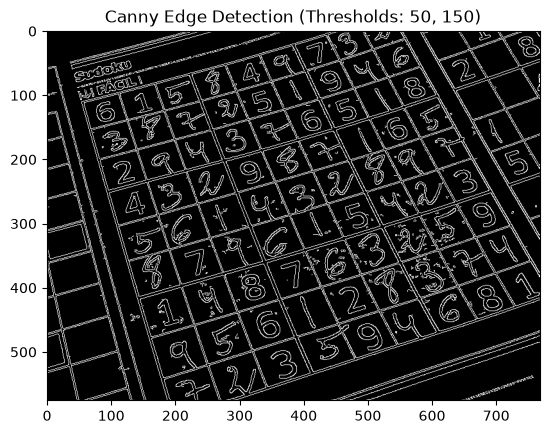

In [23]:
# Apply Canny edge detector with thresholds 50 and 150
edges_low = cv2.Canny(gray_sudoku, 50, 150)
# Set title for lower threshold Canny plot
plt.title('Canny Edge Detection (Thresholds: 50, 150)')
# Display lower threshold edges in grayscale
plt.imshow(edges_low, cmap='gray')
# Show the edge plot
plt.show()

## Task 23.3: Canny Edge Detection with Higher Thresholds (100, 200)
Apply Canny edge detector with higher hysteresis thresholds of 100 and 200, and save comparison.

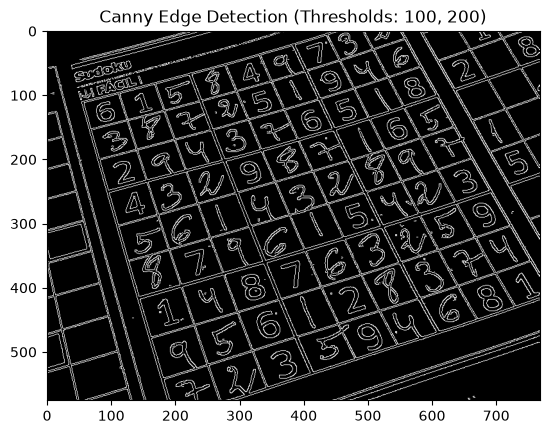

In [24]:
# Compute Canny edges with higher thresholds 100 and 200
edges_high = cv2.Canny(gray_sudoku, 100, 200)
# Set title for higher threshold Canny plot
plt.title('Canny Edge Detection (Thresholds: 100, 200)')
# Display higher threshold edges in grayscale
plt.imshow(edges_high, cmap='gray')
# Save edge detection result to outputs directory
plt.savefig('outputs/canny_edge_comparisons.png', bbox_inches='tight')

## 5. Line Detection: Standard Hough vs. Probabilistic Hough Transform
Compare standard HoughLines and probabilistic HoughLinesP on the Sudoku grid across different parameters.

## Task 24.1: Standard Hough Transform (Threshold = 150)
Detect infinite lines using cv2.HoughLines with a lower accumulator threshold of 150.

In [25]:
# Create copy of Sudoku image for drawing lines
img_h1 = img_sudoku.copy()
# Loop over detected infinite lines with threshold 150
for r, t in cv2.HoughLines(edges_low, 1, np.pi/180, 150)[:, 0][:30]:
    # Calculate first point along detected line
    pt1 = (int(r * np.cos(t) + 1000 * -np.sin(t)), int(r * np.sin(t) + 1000 * np.cos(t)))
    # Draw red line segment across image
    cv2.line(img_h1, pt1, (int(r * np.cos(t) - 1000 * -np.sin(t)), int(r * np.sin(t) - 1000 * np.cos(t))), (0, 0, 255), 2)

## Task 24.2: Display Standard Hough Lines (Threshold = 150)
Display annotated image with HoughLines detected using threshold 150 using Matplotlib.

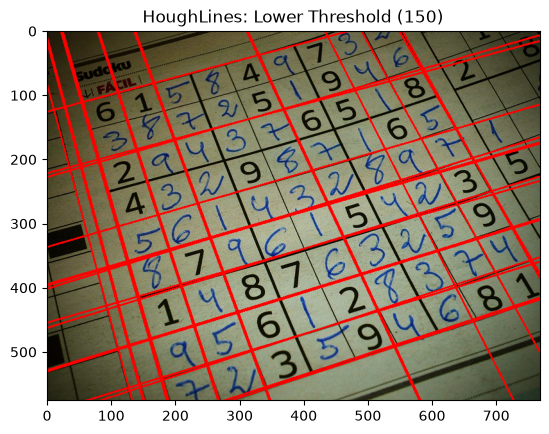

In [26]:
# Set title for lower threshold HoughLines plot
plt.title('HoughLines: Lower Threshold (150)')
# Display annotated image in RGB
plt.imshow(cv2.cvtColor(img_h1, cv2.COLOR_BGR2RGB))
# Show the image plot
plt.show()

## Task 24.3: Standard Hough Transform (Threshold = 250)
Detect infinite lines using cv2.HoughLines with a higher accumulator threshold of 250.

In [27]:
# Create copy of Sudoku image for drawing lines
img_h2 = img_sudoku.copy()
# Loop over detected infinite lines with threshold 250
for r, t in cv2.HoughLines(edges_low, 1, np.pi/180, 250)[:, 0]:
    # Calculate first point along detected line
    pt1 = (int(r * np.cos(t) + 1000 * -np.sin(t)), int(r * np.sin(t) + 1000 * np.cos(t)))
    # Draw red line segment across image
    cv2.line(img_h2, pt1, (int(r * np.cos(t) - 1000 * -np.sin(t)), int(r * np.sin(t) - 1000 * np.cos(t))), (0, 0, 255), 2)

## Task 24.4: Display Standard Hough Lines (Threshold = 250)
Display annotated image with HoughLines detected using threshold 250 using Matplotlib.

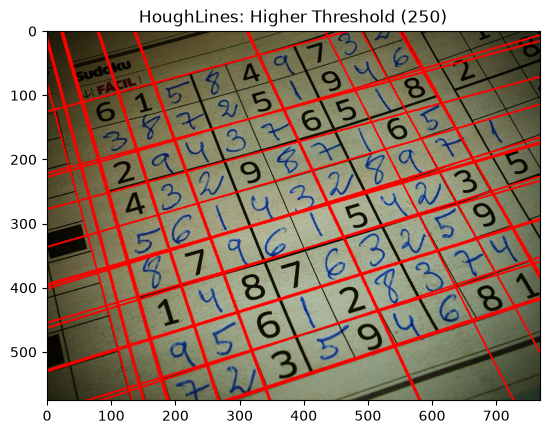

In [28]:
# Set title for higher threshold HoughLines plot
plt.title('HoughLines: Higher Threshold (250)')
# Display annotated image in RGB
plt.imshow(cv2.cvtColor(img_h2, cv2.COLOR_BGR2RGB))
# Show the image plot
plt.show()

## Task 24.5: Probabilistic Hough Transform (minLineLength = 50)
Detect line segments using cv2.HoughLinesP with a shorter minimum line length of 50.

In [29]:
# Create copy of Sudoku image for drawing line segments
img_p1 = img_sudoku.copy()
# Detect and loop over short and long line segments
for x1, y1, x2, y2 in cv2.HoughLinesP(edges_low, 1, np.pi/180, 50, minLineLength=50, maxLineGap=10)[:, 0]:
    # Draw green line segment on image
    cv2.line(img_p1, (x1, y1), (x2, y2), (0, 255, 0), 2)

## Task 24.6: Display Probabilistic Hough Lines (minLineLength = 50)
Display annotated image with line segments detected using minLineLength 50 with Matplotlib.

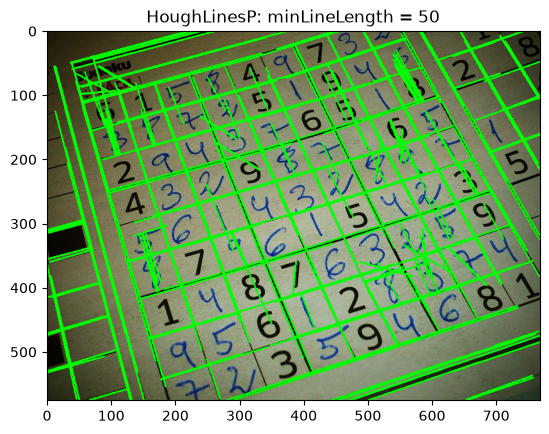

In [30]:
# Set title for shorter minLineLength plot
plt.title('HoughLinesP: minLineLength = 50')
# Display annotated image in RGB
plt.imshow(cv2.cvtColor(img_p1, cv2.COLOR_BGR2RGB))
# Show the image plot
plt.show()

## Task 24.7: Probabilistic Hough Transform (minLineLength = 150)
Detect line segments using cv2.HoughLinesP with a longer minimum line length of 150.

In [31]:
# Create copy of Sudoku image for drawing line segments
img_p2 = img_sudoku.copy()
# Detect and loop over long line segments only
for x1, y1, x2, y2 in cv2.HoughLinesP(edges_low, 1, np.pi/180, 50, minLineLength=150, maxLineGap=10)[:, 0]:
    # Draw green line segment on image
    cv2.line(img_p2, (x1, y1), (x2, y2), (0, 255, 0), 2)

## Task 24.8: Display and Save Probabilistic Hough Lines (minLineLength = 150)
Display annotated image with line segments detected using minLineLength 150 and save comparison output.

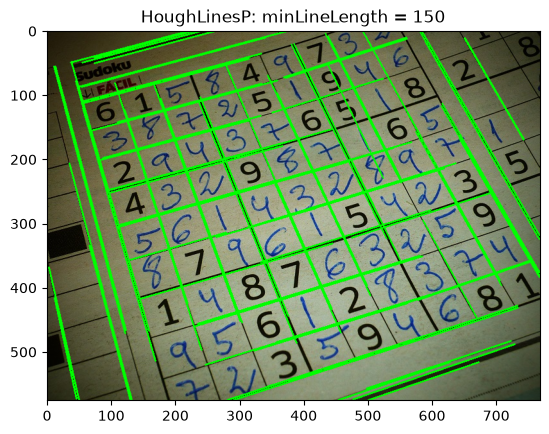

In [32]:
# Set title for longer minLineLength plot
plt.title('HoughLinesP: minLineLength = 150')
# Display annotated image in RGB
plt.imshow(cv2.cvtColor(img_p2, cv2.COLOR_BGR2RGB))
# Save Hough line comparison visualization to outputs folder
plt.savefig('outputs/hough_line_comparison.png', bbox_inches='tight')
# Show the image plot
plt.show()

### Analysis of Canny Thresholds and Hough Line Parameters
1. **Canny Hysteresis Thresholds (50:150 vs. 100:200):** Lower thresholds (50:150) capture fine edge details including inner digit strokes and subtle texture, while higher thresholds (100:200) filter out weaker gradients and retain only prominent grid boundaries.
2. **Standard Hough Accumulator Threshold (150 vs. 250):** A lower accumulator threshold (150) produces numerous candidate lines across cluttered regions, whereas a higher threshold (250) restricts detection to prominent, highly-aligned grid lines.
3. **Probabilistic Hough minLineLength (50 vs. 150):** Shorter minimum length (50 px) detects fragmented strokes and cell borders, whereas longer minimum length (150 px) filters out short number strokes and cleanly isolates continuous grid borders.

## 6. Summary and Comparative Synthesis
Synthesize the findings, operational parameters, and key trade-offs across all four computer vision tasks.

## Task 25: Synthesis and Comparative Summary
Create and display a comparative synthesis table summarizing the four computer vision techniques.

In [33]:
# Import pandas library for summary table
import pandas as pd
# Construct synthesis dictionary of computer vision techniques
summary_data = {'Task': ['Face Detection', 'Feature Matching', 'Edge Detection', 'Line Detection'], 'Technique': ['Haar Cascades', 'SIFT vs. ORB', 'Canny Algorithm', 'Standard vs. Prob. Hough'], 'Key Parameters': ['scaleFactor, minNeighbors', 'NORM_L2 vs. NORM_HAMMING', 'low/high thresholds', 'threshold, minLineLength'], 'Primary Trade-off': ['Speed vs. Pose Sensitivity', 'Accuracy vs. Real-Time Speed', 'Noise Rejection vs. Weak Edges', 'Infinite Lines vs. Segment Accuracy']}
# Create summary dataframe
df_summary = pd.DataFrame(summary_data)
# Display comparative summary table
df_summary

,Task,Technique,Key Parameters,Primary Trade-off
0,Face Detection,Haar Cascades,"scaleFactor, minNeighbors",Speed vs. Pose Sensitivity
1,Feature Matching,SIFT vs. ORB,NORM_L2 vs. NORM_HAMMING,Accuracy vs. Real-Time Speed
2,Edge Detection,Canny Algorithm,low/high thresholds,Noise Rejection vs. Weak Edges
3,Line Detection,Standard vs. Prob. Hough,"threshold, minLineLength",Infinite Lines vs. Segment Accuracy
